# Anomaly detection evaluation (AI-008)

Five transparent **rules** (R1-R5) and an **Isolation Forest risk score** with a weekly **review queue**
score every stock transaction. Eight anomalies were injected into the synthetic ledger with ground-truth
labels (`anomaly-labels.json`). The labels are used **only here**: they never reach training, rule thresholds,
the eligibility rule or the queue size. This is the second pass; the first-pass numbers (commit `5b78db1`)
are in `tests/fixtures/anomaly-baseline-v1.json` and are compared below.

**Read this first.** The injected anomalies were designed with the same ideas the rules encode (outside
business hours, a big negative adjustment, a duplicate), so the rules catch them *by construction*. The
queue's result is the informative part, and it is shown without flattering it.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent                      # ai-service/
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

ACTUAL, BASELINE, ML, SELECTED = "#444444", "#0072B2", "#D55E00", "#009E73"   # colour-blind safe
FIXTURES = ROOT / "tests" / "fixtures"

In [2]:
import json
from app.anomaly.evaluate import _find, evaluate_anomaly_detection, load_labels, queue_metrics
from app.anomaly.model import QUEUE_SIZE, fit_anomaly_model, score_ledger
from app.data.sources import CsvSource

source = CsvSource(FIXTURES)
ledger, products, warehouses = source.ledger(), source.products(), source.warehouses()
labels = load_labels(FIXTURES / "anomaly-labels.json")
profiles = json.loads((FIXTURES / "scenarios.json").read_text())
before = json.loads((FIXTURES / "anomaly-baseline-v1.json").read_text())

model = fit_anomaly_model(ledger)
scored = score_ledger(model, ledger)
evaluation = evaluate_anomaly_detection(scored, ledger, products, warehouses, labels)
related = {_find(ledger, products, warehouses, a["related"]) for a in labels["anomalies"] if a.get("related")}
print(f"{len(scored):,} transactions scored, {int(scored.eligible.sum()):,} eligible for the queue | {int(scored.flagged.sum())} flagged "
      f"(rules {int(scored.rule_flag.sum())}, queue {int(scored.model_flag.sum())}, both {int((scored.source == 'BOTH').sum())}) | {len(evaluation.labelled)} injected anomalies")

2,978 transactions scored, 2,762 eligible for the queue | 147 flagged (rules 45, queue 140, both 38) | 8 injected anomalies


## 1. Before and after

Changes in this pass, all decided before the results were seen: documented receipts and non-stock movements are
not eligible for the model; rule R5 flags an identical movement within 10 minutes; the forest's score is a risk
percentile and the top 10 eligible rows per local week form the review queue (no 0.5% cut).

In [3]:
overall = evaluation.overall.set_index("detector")
rows = []
for name in ("rules", "model", "combined"):
    old, now = before["detectors"][name], overall.loc[name]
    rows.append({"detector": name, "caught before": old["caught"], "caught after": int(now.true_positives),
                 "false positives before": old["false_positives"], "false positives after": int(now.false_positives),
                 "precision before": old["precision"], "precision after": now.precision,
                 "recall before": old["recall"], "recall after": now.recall})
pd.DataFrame(rows).set_index("detector").round(3)

,caught before,caught after,false positives before,false positives after,precision before,precision after,recall before,recall after
detector,,,,,,,,
rules,6,7,13,38,0.316,0.156,0.75,0.875
model,0,6,14,134,0.000,0.043,0.00,0.750
combined,6,8,27,139,0.182,0.054,0.75,1.000


In [4]:
by_type = evaluation.by_type.set_index("anomaly_type")
old = before["by_type_detected_rules_model_combined"]
pd.DataFrame({
    "injected": by_type["injected"],
    "rules (before -> after)": [f"{old[t][0]} -> {int(by_type.loc[t, 'rules_detected'])}" for t in by_type.index],
    "model (before -> after)": [f"{old[t][1]} -> {int(by_type.loc[t, 'model_detected'])}" for t in by_type.index],
    "combined (before -> after)": [f"{old[t][2]} -> {int(by_type.loc[t, 'combined_detected'])}" for t in by_type.index],
})

,injected,rules (before -> after),model (before -> after),combined (before -> after)
anomaly_type,,,,
DUPLICATE_ISSUE,1,0 -> 1,0 -> 1,0 -> 1
MANUAL_RECEIPT,1,1 -> 1,0 -> 1,1 -> 1
NEGATIVE_ADJUSTMENT,2,2 -> 2,0 -> 2,2 -> 2
OFF_HOURS_ISSUE,2,2 -> 2,0 -> 0,2 -> 2
SPIKE_ISSUE,2,1 -> 1,0 -> 2,1 -> 2


In [5]:
r = evaluation.ranking
print(f"Risk score, threshold-free, over {r['eligible_transactions']:,} eligible rows: ROC-AUC {r['roc_auc']:.3f} (before {before['ranking']['roc_auc']}); "
      f"average precision {r['average_precision']:.3f} (before {before['ranking']['average_precision']}) vs {r['baseline_average_precision']:.4f} for a random ranking.")
print("Labelled anomalies among the top K risk scores:", {f"top {k}": f"{v} of {r['labelled']}" for k, v in r["recall_at_k"].items()},
      "| before:", before["ranking"]["recall_at_k"])
print("The new figures are over eligible rows only; the old ones over all rows, so they are not like for like.")

Risk score, threshold-free, over 2,761 eligible rows: ROC-AUC 0.873 (before 0.8494); average precision 0.544 (before 0.03479) vs 0.0029 for a random ranking.
Labelled anomalies among the top K risk scores: {'top 10': '5 of 8', 'top 20': '5 of 8', 'top 50': '6 of 8'} | before: {'10': 0, '20': 0, '50': 2}
The new figures are over eligible rows only; the old ones over all rows, so they are not like for like.


## 2. The review queue: precision@N and recall@N

N = 10 per local week was fixed before looking at results; 5 and 20 are a sensitivity check only. A queue row that is
the original of a labelled duplicate counts as neither a hit nor a false alarm.

In [6]:
queue = queue_metrics(scored, evaluation.labelled, related)
queue.round(4)

,n_per_period,chosen_up_front,periods,queue_rows,queue_hits,precision_at_n,recall_at_n,random_precision,queue_plus_rules_rows,queue_plus_rules_hits,queue_plus_rules_precision,queue_plus_rules_recall
0,5,False,14,70,6,0.0857,0.75,0.0029,96,8,0.0833,1.0
1,10,True,14,140,6,0.0429,0.75,0.0029,147,8,0.0544,1.0
2,20,False,14,280,6,0.0214,0.75,0.0029,282,8,0.0284,1.0


In [7]:
top = scored[scored["in_queue"]].sort_values("risk_score", ascending=False).head(5)
top[["id", "type", "period", "risk_score", "queue_rank", "source", "top_features"]].assign(
    top_features=lambda d: d["top_features"].map(lambda f: "; ".join(x["feature"] for x in f) if isinstance(f, list) else f))

,id,type,period,risk_score,queue_rank,source,top_features
1308,1309,RECEIPT,2026-09-06/2026-09-12,0.999638,1.0,BOTH,share of the stock on hand that moved; movemen...
2903,2904,ISSUE,2026-10-25/2026-10-31,0.999276,1.0,BOTH,size as a multiple of the usual; size against ...
683,684,ADJUSTMENT,2026-08-23/2026-08-29,0.998914,1.0,BOTH,movement type adjustment; movement type issue;...
767,768,ADJUSTMENT,2026-08-23/2026-08-29,0.998552,2.0,BOTH,movement type adjustment; movement type issue;...
2752,2753,ADJUSTMENT,2026-10-25/2026-10-31,0.998190,2.0,BOTH,movement type issue; movement type adjustment;...


## 3. Every injected anomaly

In [8]:
evaluation.labelled[["label", "anomaly_type", "sku", "expected_detection", "rules", "model", "combined", "risk_score", "model_rank", "rule_codes"]].round(3)

,label,anomaly_type,sku,expected_detection,rules,model,combined,risk_score,model_rank,rule_codes
0,A-01,SPIKE_ISSUE,SYN-ELE-005,BOTH,True,True,True,0.999,2,R2
1,A-02,NEGATIVE_ADJUSTMENT,SYN-BRK-004,RULE,True,True,True,0.998,5,R1
2,A-03,OFF_HOURS_ISSUE,SYN-ENG-006,RULE,True,False,True,0.285,1974,R3
3,A-04,NEGATIVE_ADJUSTMENT,SYN-BRK-006,RULE,True,True,True,0.999,4,R1
4,A-05,SPIKE_ISSUE,SYN-ELE-002,BOTH,False,True,True,0.996,10,
5,A-06,DUPLICATE_ISSUE,SYN-BRK-003,MODEL,True,True,True,0.992,21,R5
6,A-07,MANUAL_RECEIPT,SYN-ENG-006,BOTH,True,True,True,1.000,1,R4
7,A-08,OFF_HOURS_ISSUE,SYN-ELE-005,RULE,True,False,True,0.706,813,R3


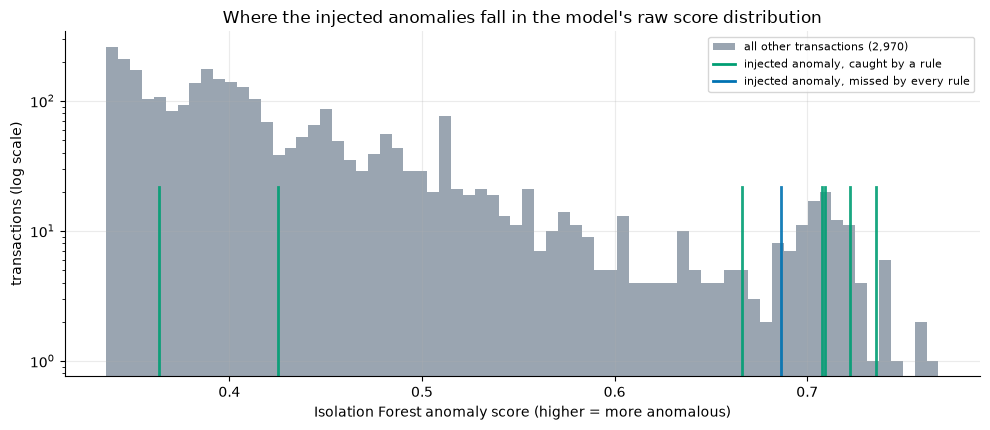

In [9]:
from app.anomaly.features import compute_features
feats = compute_features(ledger, model.stats, 6)
raw = pd.Series(model.raw_scores(feats), index=feats["id"])          # Isolation Forest score: higher = more anomalous
labelled = evaluation.labelled.set_index("id")

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.hist(raw[~raw.index.isin(labelled.index)], bins=70, color="#9aa5b1", label=f"all other transactions ({len(raw) - len(labelled):,})")
for row_id, row in labelled.iterrows():
    ax.axvline(raw[row_id], ymax=0.55, color=SELECTED if row["rules"] else BASELINE, lw=2, alpha=0.9)
ax.plot([], [], color=SELECTED, lw=2, label="injected anomaly, caught by a rule")
ax.plot([], [], color=BASELINE, lw=2, label="injected anomaly, missed by every rule")
ax.set_yscale("log"); ax.set_xlabel("Isolation Forest anomaly score (higher = more anomalous)"); ax.set_ylabel("transactions (log scale)")
ax.set_title("Where the injected anomalies fall in the model's raw score distribution")
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

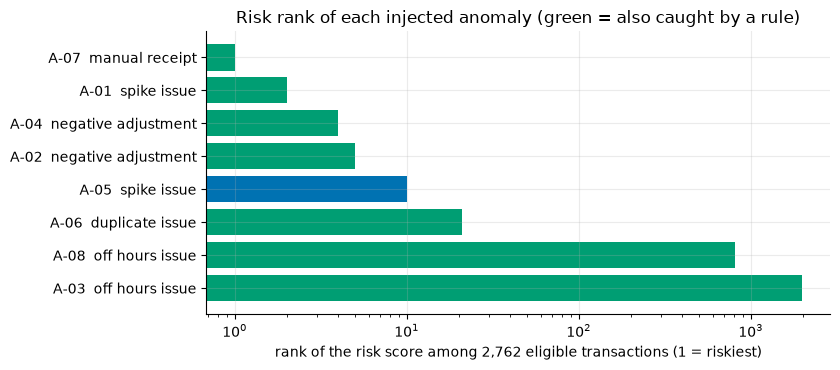

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
data = evaluation.labelled.sort_values("model_rank", ascending=False)
colors = [SELECTED if r else BASELINE for r in data["rules"]]
ax.barh(data["label"] + "  " + data["anomaly_type"].str.replace("_", " ").str.lower(), data["model_rank"], color=colors)
ax.set_xscale("log"); ax.set_xlabel(f"rank of the risk score among {int(scored.eligible.sum()):,} eligible transactions (1 = riskiest)")
ax.set_title("Risk rank of each injected anomaly (green = also caught by a rule)")
plt.tight_layout(); plt.show()

### Why the model misses the off-hours events

An Isolation Forest isolates points by random splits on features. Only a handful of transactions are outside
business hours, so in most trees' random samples that feature is constant and cannot be split on. The rule
covers them directly, which is the point of having both layers.

In [11]:
off = (feats["off_hours_distance"] > 0).to_numpy()
injected = feats["id"].isin(evaluation.labelled["id"]).to_numpy()
print(f"{int(off.sum())} of {len(feats):,} transactions are outside business hours ({100 * off.mean():.2f}%); "
      f"{int((off & injected).sum())} of them are injected anomalies.")
saw = np.mean([off[idx].any() for idx in model.forest.estimators_samples_])
print(f"Only {100 * saw:.0f}% of the {len(model.forest.estimators_samples_)} trees had an off-hours transaction in their sample; "
      f"in the other {100 * (1 - saw):.0f}% that feature is constant and cannot isolate anything.")

2 of 2,978 transactions are outside business hours (0.07%); 2 of them are injected anomalies.
Only 13% of the 300 trees had an off-hours transaction in their sample; in the other 87% that feature is constant and cannot isolate anything.


## 4. False positives: what is flagged that is not labelled

In [12]:
from app.anomaly.evaluate import categorize_false_positives, is_data_artefact
steered = {sku for sku, p in profiles["profiles"].items() if p in profiles["steeredProfiles"]}
fp = categorize_false_positives(evaluation.false_positives, ledger, labels, steered)
summary = fp.groupby(["source", "type", "likely_cause"]).size().rename("flags").reset_index().sort_values("flags", ascending=False)
print(f"{len(fp)} false positives out of {int(scored.flagged.sum())} flags (before: {before['detectors']['combined']['false_positives']} of {before['flags']['total']}) "
      f"-> precision {overall.loc['combined', 'precision']:.3f} (before {before['detectors']['combined']['precision']})")
summary

139 false positives out of 147 flags (before: 27 of 33) -> precision 0.054 (before 0.182)


,source,type,likely_cause,flags
5,MODEL,ISSUE,ordinary large movement (natural tail of the d...,62
2,BOTH,ISSUE,ordinary large movement (natural tail of the d...,30
3,MODEL,ADJUSTMENT,ordinary large movement (natural tail of the d...,22
7,MODEL,TRANSFER_IN,ordinary large movement (natural tail of the d...,6
8,MODEL,TRANSFER_OUT,ordinary large movement (natural tail of the d...,6
9,RULE,ISSUE,ordinary large movement (natural tail of the d...,5
4,MODEL,ISSUE,last-day trim: the generator landing a demo st...,3
1,BOTH,ISSUE,last-day trim: the generator landing a demo st...,2
6,MODEL,ISSUE,"steered demo product, last 12 days (synthetic ...",2
0,BOTH,ADJUSTMENT,ordinary large movement (natural tail of the d...,1


In [13]:
before_fp = pd.Series(before["false_positive_causes"], name="flags before").rename_axis("source, type and cause")
natural = fp[~fp["likely_cause"].map(is_data_artefact)]
print(f"After setting aside flags caused by how the synthetic data was built ({len(fp) - len(natural)}), {len(natural)} remain.")
before_fp

After setting aside flags caused by how the synthetic data was built (7), 132 remain.


source, type and cause
RULE ISSUE ordinary large movement     10
MODEL RECEIPT opening stock             8
MODEL RECEIPT large goods receipt       6
RULE ISSUE last-day trim                2
RULE ADJUSTMENT routine cycle count     1
Name: flags before, dtype: int64

## 5. What this does and does not show

* **Rules catch what they were written for.** The injected anomalies match the rules, so the system did not
  discover them.
* **The recall gain is mostly the eligibility rule.** Excluding receipts that carry a PO or goods-receipt link
  removes the large legitimate receipts and the opening stock from the model's competition. In a real plant it
  also makes the model blind to a wrong receipt that has a document.
* **Precision fell and workload rose.** About 147 flags instead of 33, because a fixed-size weekly queue is
  always full and R5 also fires on natural repeats. Eight anomalies in 90 days cannot show what a real queue yields.
* **Rule R2 also fires on ordinary tail events.** The 13 original rule false positives were examined by data
  fields: none is documented or a receipt, 12 are issues of 1.2 to 3.2 times the mean daily demand. A days-of-demand
  criterion would remove them but choosing it now would be tuning on seen labels; it is left to the owner.
* **N = 10, the 10-minute R5 window and the exclusion were fixed up front;** N = 5 and 20 are sensitivity only.
* **Eight labels** are far too few to tune anything. Real anomalies are rarer, subtler and unlabelled.